# Combined Results Summary

Collects the fold-level cross-validation results of every model into the same tables and figures, using the shared helpers in `src/reporting.py`. This notebook only reads saved CSV files, so it runs in seconds and can be re-run whenever a model notebook adds or updates results.

**To add results** (for example, the random-forest feature ablation or tuned model), add the CSV to `RESULT_FILES` below with a display name and selector.

Current contents:

- Linear regression: mutual-information (MI) selection at 2/4/6 features, forward selection at 2/4/6, all 8 features (notebook 02)
- Ridge regression, alpha tuned by inner CV: MI selection at 2/4/6 and all 8 (notebook 02)
- Random forest: untuned baseline, all 8 features, 5 seeds (notebook 03)

All rows use the shared seed-42 five-fold cross-validation on the development set.

In [5]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd().resolve()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import FEATURE_COLUMNS, FEATURE_COUNTS, TARGET_COLUMNS
from src.reporting import TARGET_LABELS, add_total_fit_time, format_mean_std, summarize, to_latex_table

TABLES = project_root / "results" / "tables"
FIGURES = project_root / "results" / "figures"

## Load fold-level results

Each entry: file name → (display name, feature selector). With all 8 features there is no selection, so the selector is recorded as `all`.

In [6]:
RESULT_FILES = {
    "linear_feature_ablation_cv.csv": ("Linear", "mi"),
    "linear_forward_selection_cv.csv": ("Linear", "forward"),
    "ridge_feature_ablation_cv.csv": ("Ridge", "mi"),
    "random_forest_mi_ablation_cv.csv": ("Random forest", "mi"),
}

frames = []
for file_name, (display_name, selector) in RESULT_FILES.items():
    frame = pd.read_csv(TABLES / file_name)
    frame["model"] = display_name
    frame["selector"] = selector
    frames.append(frame)

results = add_total_fit_time(pd.concat(frames, ignore_index=True))
results.loc[results["n_features"] == len(FEATURE_COLUMNS), "selector"] = "all"

# Linear MI and forward rows at 8 features would be identical; keep one copy.
results = results.drop_duplicates(
    subset=["target", "model", "selector", "n_features", "fold", "model_seed"]
)

SELECTOR_LABELS = {"mi": "MI", "forward": "forward", "all": "all"}
results["method"] = results["model"] + " (" + results["selector"].map(SELECTOR_LABELS) + ")"

print(results.groupby(["model", "selector", "n_features"]).size().rename("rows").to_string())

model          selector  n_features
Linear         all       8             10
               forward   2             10
                         4             10
                         6             10
               mi        2             10
                         4             10
                         6             10
Random forest  all       8             50
               mi        2             50
                         4             50
                         6             50
Ridge          all       8             10
               mi        2             10
                         4             10
                         6             10


## Table 1: validation accuracy

Mean ± standard deviation over the five folds (and over the five model seeds for the random forest).

In [7]:
summary = summarize(results, metrics=("rmse", "mae", "r2"), by=("target", "model", "selector", "n_features"))
summary.to_csv(TABLES / "summary_accuracy_cv.csv", index=False)

accuracy_table = None
for target in TARGET_COLUMNS:
    part = summary[summary["target"] == target].set_index(["model", "selector", "n_features"])
    columns = pd.DataFrame({
        f"{TARGET_LABELS[target]} RMSE": format_mean_std(part, "rmse", 2),
        f"{TARGET_LABELS[target]} R²": format_mean_std(part, "r2", 3),
    })
    accuracy_table = columns if accuracy_table is None else accuracy_table.join(columns)

model_order = {"Linear": 0, "Ridge": 1, "Random forest": 2}
selector_order = {"all": 0, "forward": 1, "mi": 2}
accuracy_table = (
    accuracy_table.reset_index()
    .sort_values(
        ["model", "selector", "n_features"],
        key=lambda s: s.map(model_order) if s.name == "model"
        else s.map(selector_order) if s.name == "selector" else -s,
    )
    .rename(columns={"model": "Model", "selector": "Selection", "n_features": "Features"})
)
accuracy_table["Selection"] = accuracy_table["Selection"].map(SELECTOR_LABELS)

to_latex_table(
    accuracy_table.rename(columns=lambda c: c.replace("²", "$^2$")),
    TABLES / "summary_accuracy_cv.tex",
    caption="Five-fold cross-validation accuracy on the development set (mean $\\pm$ std).",
    label="tab:cv_accuracy",
)
accuracy_table

,Model,Selection,Features,Heating RMSE,Heating R²,Cooling RMSE,Cooling R²
3,Linear,all,8,2.92 ± 0.18,0.915 ± 0.012,3.22 ± 0.20,0.883 ± 0.013
6,Linear,forward,6,2.91 ± 0.18,0.915 ± 0.013,3.21 ± 0.20,0.884 ± 0.013
5,Linear,forward,4,2.98 ± 0.15,0.911 ± 0.012,3.24 ± 0.20,0.882 ± 0.013
4,Linear,forward,2,3.70 ± 0.19,0.862 ± 0.018,3.74 ± 0.23,0.842 ± 0.020
2,Linear,MI,6,2.93 ± 0.18,0.914 ± 0.013,3.21 ± 0.20,0.884 ± 0.013
1,Linear,MI,4,4.21 ± 0.19,0.822 ± 0.024,3.97 ± 0.14,0.822 ± 0.013
0,Linear,MI,2,7.15 ± 0.18,0.488 ± 0.047,6.54 ± 0.06,0.518 ± 0.039
10,Ridge,all,8,2.92 ± 0.18,0.915 ± 0.012,3.22 ± 0.20,0.883 ± 0.013
9,Ridge,MI,6,2.93 ± 0.18,0.914 ± 0.013,3.21 ± 0.20,0.884 ± 0.013
8,Ridge,MI,4,4.21 ± 0.19,0.822 ± 0.024,3.97 ± 0.15,0.822 ± 0.013


## Table 2: computational cost

Times in milliseconds, averaged over folds and both targets. *Training* is fitting the final model on its selected features; *selection* and *tuning* are the feature-selection and hyperparameter-search steps; *total fit* is their sum, the full cost of producing one model.

Note: the random-forest baseline times were measured once per fit with all CPU cores (`n_jobs=-1`), while linear and ridge times are medians of 20 repeats. The difference in method does not affect the size of the gap (roughly 100× in training time).

In [8]:
time_columns = ["train_time", "selection_time", "tuning_time", "total_fit_time", "prediction_time"]
cost = (
    results.groupby(["model", "selector", "n_features"])[time_columns].mean()
    .mul(1000)
    .reset_index()
)
cost.to_csv(TABLES / "summary_cost_cv.csv", index=False)

cost_table = (
    cost.sort_values(
        ["model", "selector", "n_features"],
        key=lambda s: s.map(model_order) if s.name == "model"
        else s.map(selector_order) if s.name == "selector" else -s,
    )
    .rename(columns={
        "model": "Model", "selector": "Selection", "n_features": "Features",
        "train_time": "Training (ms)", "selection_time": "Selection (ms)",
        "tuning_time": "Tuning (ms)", "total_fit_time": "Total fit (ms)",
        "prediction_time": "Prediction (ms)",
    })
)
cost_table["Selection"] = cost_table["Selection"].map(SELECTOR_LABELS)
cost_table = cost_table.round(1)

to_latex_table(
    cost_table.astype(str),
    TABLES / "summary_cost_cv.tex",
    caption="Mean computational cost per cross-validation fit (milliseconds).",
    label="tab:cv_cost",
)
cost_table

,Model,Selection,Features,Training (ms),Selection (ms),Tuning (ms),Total fit (ms),Prediction (ms)
0,Linear,all,8,2.1,0.0,0.0,2.1,0.8
3,Linear,forward,6,3.4,597.7,0.0,601.1,1.7
2,Linear,forward,4,3.5,512.7,0.0,516.2,1.5
1,Linear,forward,2,3.8,362.3,0.0,366.1,1.4
6,Linear,MI,6,2.0,42.2,0.0,44.2,0.8
5,Linear,MI,4,1.8,36.5,0.0,38.2,0.7
4,Linear,MI,2,1.8,38.0,0.0,39.8,0.7
11,Ridge,all,8,7.7,0.0,242.4,250.2,2.5
14,Ridge,MI,6,8.6,69.0,1114.4,1191.9,2.4
13,Ridge,MI,4,5.8,59.4,990.0,1055.1,1.8


## Figure A (draft): validation RMSE vs. number of features

Error bars are ± one standard deviation across folds. The random forest currently has results only for all 8 features; its line will fill in when the random-forest ablation is added.

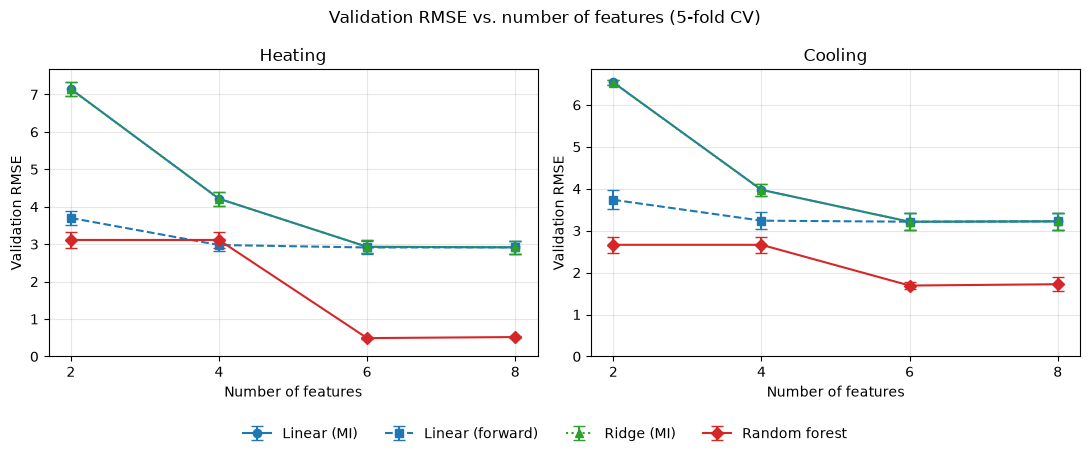

In [9]:
STYLES = {
    ("Linear", "mi"): dict(color="tab:blue", marker="o", linestyle="-", label="Linear (MI)"),
    ("Linear", "forward"): dict(color="tab:blue", marker="s", linestyle="--", label="Linear (forward)"),
    ("Ridge", "mi"): dict(color="tab:green", marker="^", linestyle=":", label="Ridge (MI)"),
    ("Random forest", "mi"): dict(color="tab:red", marker="D", linestyle="-", label="Random forest"),
}

def series_for(data, model, selector):
    # The shared 8-feature point belongs to every selector's line.
    rows = data[(data["model"] == model) & (data["selector"].isin([selector, "all"]))]
    return rows.sort_values("n_features")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, target in zip(axes, TARGET_COLUMNS):
    data = summary[summary["target"] == target]
    for (model, selector), style in STYLES.items():
        rows = series_for(data, model, selector)
        if rows.empty:
            continue
        ax.errorbar(rows["n_features"], rows["rmse_mean"], yerr=rows["rmse_std"], capsize=4, **style)

    ax.set(
        title=TARGET_LABELS[target],
        xlabel="Number of features",
        ylabel="Validation RMSE",
        xticks=FEATURE_COUNTS,
    )
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Validation RMSE vs. number of features (5-fold CV)")
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(FIGURES / "summary_rmse_vs_features.png", dpi=200, bbox_inches="tight")
plt.show()

## Figure B (draft): accuracy vs. computational cost

Each point is one model and feature count; the number beside it is the feature count. The 8-feature linear and ridge points have no selection step, so they appear once for each selector. Linear and ridge with MI selection reach the same accuracy (their markers overlap in Figure A), so ridge's extra cost buys nothing here. Left: training time of the final model only. Right: total fitting cost including feature selection and hyperparameter tuning. Time axes are logarithmic.

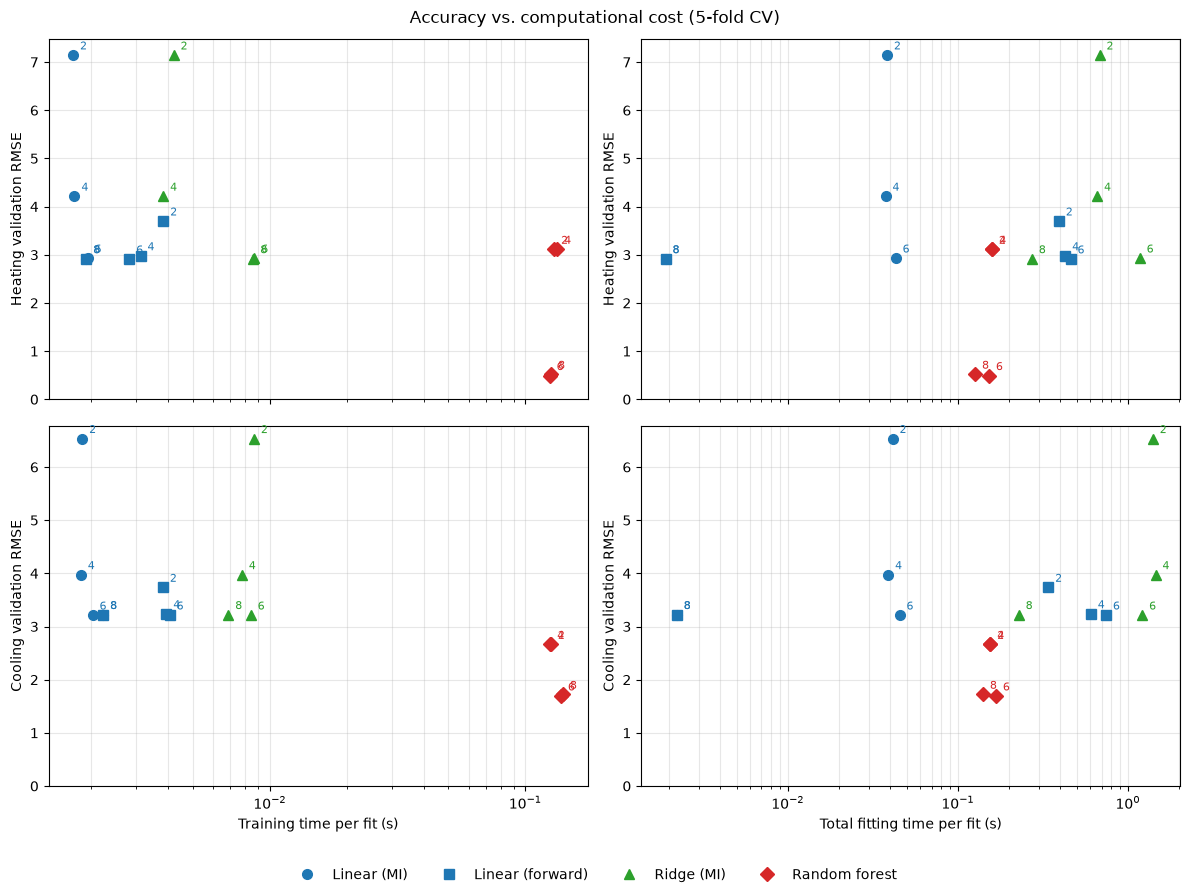

In [10]:
points = (
    results.groupby(["target", "model", "selector", "n_features"])
    .agg(rmse=("rmse", "mean"), train_time=("train_time", "mean"), total_fit_time=("total_fit_time", "mean"))
    .reset_index()
)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex="col")

for row, target in enumerate(TARGET_COLUMNS):
    data = points[points["target"] == target]
    for col, (time_column, time_label) in enumerate([
        ("train_time", "Training time per fit (s)"),
        ("total_fit_time", "Total fitting time per fit (s)"),
    ]):
        ax = axes[row, col]
        for (model, selector), style in STYLES.items():
            rows = series_for(data, model, selector)
            if rows.empty:
                continue
            ax.plot(rows[time_column], rows["rmse"], **{**style, "linestyle": "none", "markersize": 7})
            for _, point in rows.iterrows():
                ax.annotate(
                    str(point["n_features"]), (point[time_column], point["rmse"]),
                    textcoords="offset points", xytext=(5, 4), fontsize=8, color=style["color"],
                )
        ax.set(xscale="log", ylabel=f"{TARGET_LABELS[target]} validation RMSE")
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.3, which="both")
        if row == 1:
            ax.set_xlabel(time_label)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Accuracy vs. computational cost (5-fold CV)")
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIGURES / "summary_accuracy_vs_cost.png", dpi=200, bbox_inches="tight")
plt.show()

## Notes for the report

- These are cross-validation results on the development set. Held-out test results will be added once all model configurations are fixed.
- Design-grouped cross-validation (notebook 04) is the estimate for unseen building designs; it should be reported alongside these random-fold results.